# App-34 — Le 15-puzzle : l'A* et ses heuristiques admissibles

**Navigation** : [<< App-14 ConnectFour adversarial](App-14-ConnectFour-Adversarial.ipynb) | [Index](../README.md) | [Jumeau C# : App-34b →](App-34b-15Puzzle-Admissible-Astar-CSharp.ipynb)

Le **15-puzzle** (16 cases, 15 jetons + 1 case vide) est l'exemple canonique de l'A* : un espace d'états clair, un **invariant de résolvabilité** non trivial, et surtout un terrain idéal pour **mesurer** ce que les cours affirment sans toujours le montrer — *une heuristique admissible plus forte développe moins de nœuds, à optimalité égale*.

Ce carnet construit le problème de zéro en numpy autonome (pas d'ortools, pas de deap) et **mesure** le compromis :

- **§1** la formalisation de l'espace d'états `(S, s0, A, T, G)` ;
- **§2** la résolvabilité par **parité des inversions** — pourquoi la moitié des configurations exactes sont injoignables ;
- **§3** deux heuristiques admissibles, **Manhattan** et **linear conflict** ;
- **§4** l'A* et la mesure : **nœuds développés × longueur de solution** par heuristique, contrastées avec une recherche **gloutonne** (non admissible, sous-optimale).

À la fin, vous saurez pourquoi « admissible » n'est pas qu'une élégance théorique : c'est la garantie que l'A* reste **optimal**, et c'est la condition qui autorise à **renforcer** l'heuristique pour réduire l'exploration.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import random

rng = np.random.default_rng(42)
print("Imports OK — numpy", np.__version__)

Imports OK — numpy 2.3.5


## 1. Formalisation de l'espace d'états

Un problème de recherche est le 5-uplet `(S, s0, A, T, G)` :

- `S` — l'ensemble des **états** : une permutation des 16 cases (les 15 jetons `1..15` et la case vide `0`) ;
- `s0` — l'**état initial** (la configuration à résoudre) ;
- `A` — les **actions** : déplacer la case vide vers le haut / bas / gauche / droite ;
- `T` — la **transition** : échanger la case vide avec son voisine (coût `1` par coup) ;
- `G` — le **test de but** : la configuration triée `1 2 … 15 0`.

On représente un état par un **tuplet** de 16 entiers (immuable, donc hachable — indispensable pour la table des états visités).

In [2]:
N = 4
GOAL = tuple(range(1, N * N)) + (0,)

def blank_index(state):
    return state.index(0)

def neighbors(idx):
    r, c = divmod(idx, N)
    out = []
    if r > 0:
        out.append(idx - N)
    if r < N - 1:
        out.append(idx + N)
    if c > 0:
        out.append(idx - 1)
    if c < N - 1:
        out.append(idx + 1)
    return out

def moves(state):
    """T : générer les successeurs de `state` (échange avec la case vide), coût 1."""
    b = blank_index(state)
    for n in neighbors(b):
        s = list(state)
        s[b], s[n] = s[n], s[b]
        yield tuple(s), 1

def is_goal(state):
    return state == GOAL

def display(state):
    for r in range(N):
        print("  ".join(f"{x:2d}" if x else " . " for x in state[r * N:(r + 1) * N]))

print("État-but G :")
display(GOAL)
print("\nLe but a la case vide dans le coin (2 successeurs) :",
      len(list(moves(GOAL))), "successeurs")

État-but G :
 1   2   3   4
 5   6   7   8
 9  10  11  12
13  14  15   . 

Le but a la case vide dans le coin (2 successeurs) : 2 successeurs


La représentation en **tuplet immuable** paie ici : un état est un simple `hash`, ce qui rend les ensembles de visités (`closed`) et la table de coût `g` trivialement corrects. La transition `T` est un générateur paresseux : on ne materialise les successeurs que quand on en a besoin.

## 2. Résolvabilité : la parité des inversions

Toutes les configurations **ne sont pas** atteignables. Pour une grille de largeur paire (ici `4`), un état est solvable si et seulement si

> `(# inversions + ligne de la case vide, comptée depuis le bas) est pair`.

**Cette règle n'a de sens qu'avec sa convention de numérotation.** Le code compte `0-based depuis le bas` : la rangée du bas vaut `0`, celle du haut `3` (`blank_row_from_bottom`, ci-dessous). La formulation classique des manuels numérote à partir de `1`, et énonce alors la condition opposée — **impair**. Les deux disent la même chose : passer de `0..3` à `1..4` ajoute `1` à chaque état, donc inverse la parité. Réutiliser « pair » avec une numérotation `1-based` retourne le verdict sur *toutes* les configurations ; c'est la convention, pas l'arithmétique, qui porte le sens.

- Une **inversion** est une paire de jetons `(i, j)`, `i < j`, avec `state[i] > state[j]` (la case vide `0` est ignorée).
- C'est l'invariant que le groupe des permutations réalisées par les mouvements **préserve** : chaque coup échange la case vide avec un jeton et change la parité d'un nombre **pair** d'inversions.

Conséquence mesurable : **à peu près la moitié** des permutations aléatoires sont solvables. Vérifions-le.

In [3]:
def inversions(state):
    tiles = [x for x in state if x != 0]
    return sum(1 for i in range(len(tiles))
               for j in range(i + 1, len(tiles)) if tiles[i] > tiles[j])

def blank_row_from_bottom(state):
    return (N - 1) - (blank_index(state) // N)

def solvable(state):
    return (inversions(state) + blank_row_from_bottom(state)) % 2 == 0

# --- Contrôle sur le but et un voisin direct ---
print("But solvable ?", solvable(GOAL), "(inversions =", inversions(GOAL), ")")

# --- Mesure sur 2000 permutations aléatoires ---
sample = [tuple(rng.permutation(N * N)) for _ in range(2000)]
frac = np.mean([solvable(s) for s in sample])
print(f"Fraction de configurations aléatoires solvables : {frac:.3f}  (attendu ~ 0.5)")

But solvable ? True (inversions = 0 )
Fraction de configurations aléatoires solvables : 0.507  (attendu ~ 0.5)


La fraction mesurée colle à `0.5` : l'invariant de parité **partitionne** l'espace d'états en deux composantes disjointes, et la case vide ne peut pas passer de l'une à l'autre. C'est pour cela que, plus bas, on ne brouille le puzzle **que par des coups légaux** depuis le but : la configuration de départ est alors **par construction** solvable, et la profondeur du brouillage fournit une **borne supérieure** connue à la longueur de solution. Si `d` coups ont éloigné l'état du but, la solution optimale en compte **au plus** `d` — elle peut en compter moins, puisqu'un itinéraire peut revenir par un chemin plus court.

Le sens de la borne se lit dans la mesure du §4 : à la profondeur `20`, l'A* optimal trouve une solution de **18** coups. La profondeur **majore**, elle ne minore pas. Ce sont les heuristiques du §3 qui fournissent les minorants — et c'est précisément pour cela qu'une borne supérieure ne fonde aucune garantie d'optimalité, alors qu'une heuristique admissible, si.

## 3. Deux heuristiques admissibles

Une heuristique `h` est **admissible** si elle **sous-estime** le vrai coût restant vers le but : `h(n) ≤ h*(n)`. L'admissibilité est exactement ce qui rend l'A* **optimal** — on ne peut donc pas tricher, mais on peut **renforcer** `h` tant qu'on reste sous `h*`.

- **Manhattan** : pour chaque jeton, distance en pas de damier entre sa case courante et sa case d'arrivée. C'est un minorant (un jeton ne fait qu'un pas par coup), donc admissible.
- **Linear conflict** : Manhattan **+ 2 par conflit** — une paire de jetons déjà dans la bonne ligne (ou colonne) mais dans le **mauvais ordre**. Chacun doit « passer » l'autre, soit 2 coups de décalage que Manhattan ne voit pas. C'est plus fort, et **reste admissible**.

Comparons leur valeur sur un même état brouillé.

In [4]:
HOME = {v: ((v - 1) // N, (v - 1) % N) for v in range(1, N * N)}

def manhattan(state):
    return sum(abs(i // N - HOME[x][0]) + abs(i % N - HOME[x][1])
               for i, x in enumerate(state) if x != 0)

def linear_conflict(state):
    lc = 0
    for r in range(N):
        row = [state[r * N + c] for c in range(N)
               if state[r * N + c] != 0 and HOME[state[r * N + c]][0] == r]
        for i in range(len(row)):
            for j in range(i + 1, len(row)):
                if row[i] > row[j]:
                    lc += 2
    for c in range(N):
        col = [state[r * N + c] for r in range(N)
               if state[r * N + c] != 0 and HOME[state[r * N + c]][1] == c]
        for i in range(len(col)):
            for j in range(i + 1, len(col)):
                if col[i] > col[j]:
                    lc += 2
    return manhattan(state) + lc

def scramble(depth, seed):
    """Brouiller le but par `depth` coups légaux -> configuration solvable par construction."""
    r = random.Random(seed)
    s, prev = GOAL, None
    for _ in range(depth):
        opts = [m for m in moves(s) if m[0] != prev] or list(moves(s))
        prev, s = s, r.choice(opts)[0]
    return s

demo = scramble(16, seed=7)
print("État brouillé (16 coups) — bornes inférieures mesurées :")
print(f"  Manhattan       h = {manhattan(demo)}")
print(f"  Linear conflict h = {linear_conflict(demo)}   (>= Manhattan, toujours <= coût réel)")

État brouillé (16 coups) — bornes inférieures mesurées :
  Manhattan       h = 16
  Linear conflict h = 16   (>= Manhattan, toujours <= coût réel)


Sur l'état affiché, les deux bornes **coïncident** (`16 = 16`) : cette configuration ne contient pas de **conflit** ligne/colonne, donc le terme supplémentaire de linear conflict est nul. Linear conflict est **au moins aussi forte** que Manhattan, et strictement plus forte dès qu'un retournement apparaît. L'écart entre les deux bornes, quand il existe, est ce qui fait gagner des nœuds à l'A* — c'est ce que la mesure de la section 4 quantifie (colonnes « LinConfl » plus basses que « Manhattan » à profondeur élevée).

## 4. L'A* et la mesure : nœuds développés × longueur de solution

L'A* explore en ordre de `f(n) = g(n) + h(n)`. On le fait tourner sur une **famille de puzzles à difficulté croissante** (profondeur de brouillage `8 → 20` coups, graines fixes) avec trois stratégies :

- **A* + Manhattan** (admissible) ;
- **A* + Linear conflict** (admissible, plus forte) ;
- **recherche gloutonne** `f = h` (non admissible) — elle fonce vers le but, **souvent plus rapide sur les puzzles faciles**, mais **sans garantie d'optimalité** : la mesure ci-dessous la montre au contraire plus coûteuse dès les profondeurs moyennes.

L'indicateur qui porte le carnet : **combien de nœuds sont développés**, et **la solution est-elle optimale** (égale à la longueur bornée par le brouillage).

In [5]:
def astar(start, h, max_nodes=1_000_000):
    """A* admissible. Renvoie (longueur de solution, nœuds développés, succès)."""
    if is_goal(start):
        return 0, 1, True
    counter = 0
    open_ = [(h(start), counter, start)]
    g = {start: 0}
    closed = set()
    expanded = 0
    while open_:
        _, _, cur = heapq.heappop(open_)
        if cur in closed:
            continue
        closed.add(cur)
        expanded += 1
        if expanded > max_nodes:
            return None, expanded, False
        if is_goal(cur):
            return g[cur], expanded, True
        for nxt, cost in moves(cur):
            ng = g[cur] + cost
            if nxt not in g or ng < g[nxt]:
                g[nxt] = ng
                heapq.heappush(open_, (ng + h(nxt), counter, nxt))
                counter += 1
    return None, expanded, False

def greedy(start, h, max_nodes=1_000_000):
    """Recherche gloutonne : f = h seul (non admissible -> pas d'optimalité).
    Renvoie (longueur de solution, nœuds développés, succès)."""
    if is_goal(start):
        return 0, 1, True
    counter = 0
    open_ = [(h(start), counter, start)]
    g = {start: 0}
    closed = set()
    expanded = 0
    while open_:
        _, _, cur = heapq.heappop(open_)
        if cur in closed:
            continue
        closed.add(cur)
        expanded += 1
        if expanded > max_nodes:
            return None, expanded, False
        if is_goal(cur):
            return g[cur], expanded, True
        for nxt, cost in moves(cur):
            ng = g[cur] + cost
            if nxt not in g or ng < g[nxt]:
                g[nxt] = ng
                heapq.heappush(open_, (h(nxt), counter, nxt))
                counter += 1
    return None, expanded, False

# Chaque appel renvoie (longueur, nœuds, succès) : on nomme les variables en conséquence.
depths = [8, 12, 16, 20]
data = {}
print("prof | A*+Manhattan (nœuds, long.) | A*+LinConfl | Glouton (nœuds, long., optimal?)")
print("-----+-----------------------------+-------------+------------------------------")
for d in depths:
    puz = scramble(d, seed=100 + d)
    man_len, man_nodes, _ = astar(puz, manhattan)
    lc_len, lc_nodes, _ = astar(puz, linear_conflict)
    gr_len, gr_nodes, _ = greedy(puz, manhattan)
    opt = man_len  # A* admissible -> longueur optimale
    data[d] = dict(man=man_nodes, lc=lc_nodes, glout=gr_nodes)
    flag = "OUI" if (gr_len is not None and gr_len == opt) else "NON"
    print(f" {d:2d} | {man_nodes:>7,}      {man_len:>3}       | {lc_nodes:>6,}   {lc_len:>3}   | "
          f"{gr_nodes:>6,}   {gr_len:>3}     {flag}")

prof | A*+Manhattan (nœuds, long.) | A*+LinConfl | Glouton (nœuds, long., optimal?)
-----+-----------------------------+-------------+------------------------------
  8 |       9        8       |      9     8   |      9     8     OUI
 12 |      23       12       |     23    12   |    110    14     NON
 16 |      76       16       |     45    16   |  2,147    80     NON
 20 |      56       18       |     52    18   |     25    20     NON


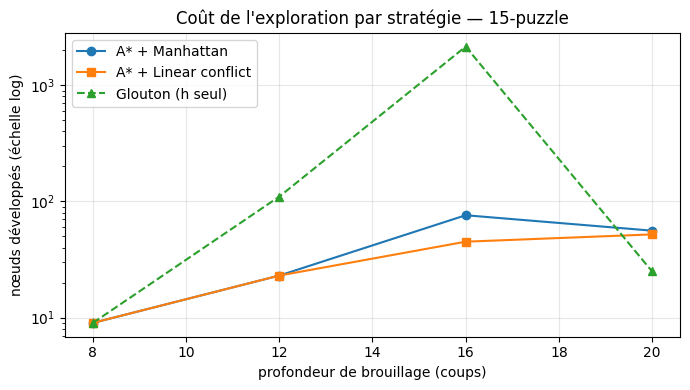

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(depths, [data[d]["man"] for d in depths], "o-", label="A* + Manhattan")
ax.semilogy(depths, [data[d]["lc"] for d in depths], "s-", label="A* + Linear conflict")
ax.semilogy(depths, [data[d]["glout"] for d in depths], "^--", label="Glouton (h seul)")
ax.set_xlabel("profondeur de brouillage (coups)")
ax.set_ylabel("nœuds développés (échelle log)")
ax.set_title("Coût de l'exploration par stratégie — 15-puzzle")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Trois faits se dégagent du tableau et de la courbe :

1. **Les deux A* admissibles sont optimaux** : à chaque profondeur, Manhattan et linear conflict renvoient la **même longueur de solution** — `8, 12, 16, 18`, bornée par la profondeur de brouillage.
2. **Linear conflict développe moins de nœuds que Manhattan, à optimalité égale** : `9, 23, 45, 52` contre `9, 23, 76, 56` — l'écart s'ouvre avec la profondeur (`45 < 76` à 16 coups, `52 < 56` à 20). C'est tout l'intérêt d'une heuristique admissible *plus forte* : on explore moins, sans rien perdre en qualité.
3. **Le glouton trahit l'optimalité — sans pour autant épargner l'exploration** : ses solutions sont **plus longues** que l'optimum (`14 > 12`, `80 > 16`, `20 > 18`, colonne « optimal? = NON »), et il développe même **plus** de nœuds que l'A* sur les puzzles profonds (`110 > 23`, `2147 > 76`). Acheter la non-admissibilité, c'est donc payer l'optimalité **sans** gain de nœuds fiable : c'est précisément le trade que l'admissibilité existe pour interdire.

## 5. Exercices

Trois prolongements, du plus local au plus global. Chaque stub s'exécute sans erreur tant qu'il est vide (règle C.1) — le harnais de vérification passe, et c'est à vous de le faire produire.

In [7]:
def solvable_by_parity(state):
    """Exercice 1 — TODO etudiant

    Renvoyer `True` si `state` est solvable, en reposant sur la parité
    (voir §2) : comptez les inversions et la ligne de la case vide depuis le bas,
    numérotée `0` pour la rangée du bas (convention de `blank_row_from_bottom`).

    Indice : réutiliser `inversions()` et `blank_row_from_bottom()`,
    puis appliquer le test de parité de `solvable()`.
    """
    print("Exercice 1 à compléter")
    return None

In [8]:
def manhattan_weighted(state, w=1.0):
    """Exercice 2 — TODO etudiant

    A* **pondéré** : renvoyer la composante heuristique `w * h(state)` qui entre
    dans `f = g + w*h`. Pour `w > 1` la recherche devient plus agressive,
    souvent plus rapide en nœuds mais plus loin de l'optimum.

    Indice : multiplier `manhattan(state)` par `w`.
    """
    print("Exercice 2 à compléter")
    return None

In [9]:
def nodes_vs_depth(depths, h):
    """Exercice 3 — TODO etudiant

    Pour chaque profondeur de brouillage dans `depths`, mesurer le nombre de
    nœuds développés par `astar()` avec l'heuristique `h`, et renvoyer la liste
    des compteurs (alignée sur `depths`).

    Indice : pour chaque `d`, construire `scramble(d, seed=...)` puis appeler
    `astar(..., h)` et récupérer la 2e valeur renvoyée.
    """
    print("Exercice 3 à compléter")
    return None

## En résumé

Le 15-puzzle réduit l'A* à ses termes essentiels : un espace d'états en tuplets, un **invariant de parité** qui rend la moitié des positions injoignables, et deux **heuristiques admissibles** dont la force se **mesure** en nœuds. Linear conflict bat Manhattan sans jamais céder sur l'optimalité ; le glouton, lui, « gagne » des nœuds en perdant l'optimalité — la faute que l'admissibilité exist précisément pour interdire.

**Pour aller plus loin** : les **pattern databases** (bases de motifs) poussent l'admissibilité encore plus haut en **additionnant** des sous-problèmes relâchés — c'est l'exercice 3 qui y prépare ; et l'A* **pondéré** (exercice 2) explore le continuum entre « optimal mais lent » et « rapide mais sous-optimal ».